In [37]:
from PIL import Image
from skimage import color
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [3]:
image = Image.open("Images/image_one.jpg")

In [4]:
print(image.size)
print(image.mode)

(3648, 2736)
RGB


In [6]:
import numpy as np
image_array = np.asarray(image)
print(image_array.shape)

(2736, 3648, 3)


In [7]:
print(image_array[0, 0])

[  0  79 243]


In [8]:
print(image_array[100, 100])

[  0  71 248]


In [9]:
print(image_array[0:3, 0:3])

[[[  0  79 243]
  [  0  73 241]
  [  0  66 239]]

 [[  0  73 244]
  [  0  71 242]
  [  0  66 241]]

 [[  3  70 249]
  [  2  69 248]
  [  2  68 250]]]


## Experiment 001: Representing an Image as Data

### Objective
Understand how a digital RGB image is represented numerically.

### Observation
The image has a shape of (2736, 3648, 3), meaning it contains
2736 rows, 3648 columns, and 3 color channels (RGB).

Each pixel can be accessed using its row and column position
and contains three numerical values representing red, green,
and blue.

### Key Insight
A color image can be represented as a NumPy array where each
pixel is represented by an RGB vector.

### Implication for our project
The system needs to reduce millions of pixel values into a
small number of representative colors that can form a useful
palette.

In [10]:
print(image_array.dtype)

uint8


In [11]:
print(image_array.min())
print(image_array.max())

0
255


### Additional Observations

The image array has a dtype of uint8, meaning each RGB
channel is represented as an unsigned 8-bit integer.

The minimum channel value is 0 and the maximum is 255.

Therefore, each pixel is represented by three values in the
range 0–255:

[R, G, B]

This means the image can be treated as numerical data and
analyzed computationally.

### New Question

How should we measure similarity between colors so that we
can group similar pixels and extract representative colors?

In [15]:
image_hsv = color.rgb2hsv(image_array / 255.0)

In [16]:
print(image_hsv.shape)
print(image_hsv[0, 0])

(2736, 3648, 3)
[0.61248285 1.         0.95294118]


In [17]:
image_lab = color.rgb2lab(image_array / 255.0)

In [18]:
print(image_lab.shape)
print(image_lab[0, 0])

(2736, 3648, 3)
[ 41.31122355  45.15095376 -86.13177177]


## Experiment 002: Exploring Color Spaces

### Question
Which color representation is most useful for analyzing
similarity between colors?

### RGB
Useful for representing the original image and its pixel
values, but numerical distance in RGB does not perfectly
represent human perception of color difference.

### HSV
Represents color using hue, saturation and value, which can
be useful for reasoning about color characteristics.

### LAB
Separates lightness from two color dimensions and provides
color-difference methods that are more closely related to
perceptual color comparison.

### Hypothesis
LAB may be useful for measuring color similarity, while RGB
may remain useful for representing the source image.

### Status
No final color-space decision has been made yet.

In [19]:
pixels = image_array.reshape(-1, 3)

print(pixels.shape)

(9980928, 3)


In [20]:
unique_colors = np.unique(pixels, axis=0)

print(unique_colors.shape)

(812899, 3)


In [21]:
colors, counts = np.unique(pixels, axis=0, return_counts=True)

print(colors.shape)
print(counts.shape)

(812899, 3)
(812899,)


In [22]:
top_indices = np.argsort(counts)[-10:][::-1]

for i in top_indices:
    print(colors[i], counts[i])

[128 128 128] 10305
[  0  15 110] 6871
[  0  18 120] 5825
[  1  14 110] 4994
[  0  13 109] 4977
[  1  16 111] 4825
[  0  12 114] 4639
[  0  11 103] 4588
[  0  10 108] 4228
[  2  15 111] 4208


In [23]:
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(pixels),
    size=50_000,
    replace=False
)

sample_pixels = pixels[sample_indices]

print(sample_pixels.shape)

(50000, 3)


In [24]:
sample_colors, sample_counts = np.unique(
    sample_pixels,
    axis=0,
    return_counts=True
)

print(sample_colors.shape)

(28378, 3)


In [25]:
full_mean = pixels.mean(axis=0)
sample_mean = sample_pixels.mean(axis=0)

print("Full image mean:", full_mean)
print("Sample mean:", sample_mean)

Full image mean: [ 60.49001826  59.6903835  138.93479204]
Sample mean: [ 60.12976  59.41726 139.15912]


In [26]:
color_a = np.array([10, 20, 100])
color_b = np.array([15, 25, 105])

distance = np.linalg.norm(color_a - color_b)

print(distance)

8.660254037844387


In [27]:
from skimage import color

color_a = np.array([10, 20, 100], dtype=np.uint8)
color_b = np.array([15, 25, 105], dtype=np.uint8)

colors_rgb = np.array([[color_a, color_b]])

colors_lab = color.rgb2lab(colors_rgb / 255.0)

print("Color A LAB:", colors_lab[0, 0])
print("Color B LAB:", colors_lab[0, 1])

Color A LAB: [ 12.50943676  29.19617152 -47.2615683 ]
Color B LAB: [ 14.49207575  28.20568649 -47.27525718]


In [28]:
lab_distance = np.linalg.norm(
    colors_lab[0, 0] - colors_lab[0, 1]
)

print("LAB distance:", lab_distance)

LAB distance: 2.216326992169157


In [32]:
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_3.fit(sample_pixels)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[[ 17

In [33]:
print("Centroids:")
print(kmeans_3.cluster_centers_)

print("Inertia:")
print(kmeans_3.inertia_)

Centroids:
[[ 17.29006969  26.4814351  126.4713088 ]
 [209.04117306 121.5634993   44.82495237]
 [  8.46418895  51.9942232  209.28628393]]
Inertia:
141661658.85981303


In [34]:
print("Centroids:")
print(kmeans_3.cluster_centers_)

print("\nInertia:")
print(kmeans_3.inertia_)

Centroids:
[[ 17.29006969  26.4814351  126.4713088 ]
 [209.04117306 121.5634993   44.82495237]
 [  8.46418895  51.9942232  209.28628393]]

Inertia:
141661658.85981303


In [35]:
inertias = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(sample_pixels)
    inertias.append(kmeans.inertia_)

    print(f"K={k}: inertia={kmeans.inertia_}")

K=2: inertia=212512203.5037547
K=3: inertia=141661658.85981303
K=4: inertia=101059061.45202613
K=5: inertia=72573344.93903679
K=6: inertia=60650279.28733879
K=7: inertia=50953660.234835856
K=8: inertia=44860333.52850142


In [38]:
k_values = range(2, 9)

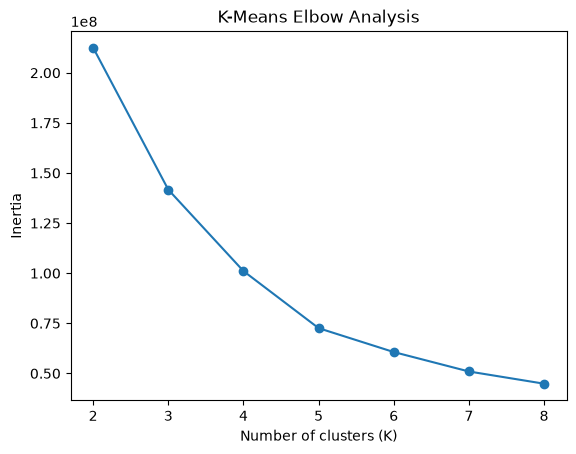

In [40]:
plt.plot(k_values, inertias, marker="o")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Analysis")
plt.show()

In [41]:
def get_palette(k, pixels):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(pixels)
    
    return kmeans.cluster_centers_

In [42]:
palette_3 = get_palette(3, sample_pixels)
palette_5 = get_palette(5, sample_pixels)
palette_7 = get_palette(7, sample_pixels)

print("K=3")
print(palette_3)

print("\nK=5")
print(palette_5)

print("\nK=7")
print(palette_7)

K=3
[[ 17.29006969  26.4814351  126.4713088 ]
 [209.04117306 121.5634993   44.82495237]
 [  8.46418895  51.9942232  209.28628393]]

K=5
[[  6.73658664  51.37865344 209.85224426]
 [246.83576347 166.78716079  23.28756582]
 [ 11.40459823  23.97799087 127.429669  ]
 [150.14312751 106.13058907 130.65128933]
 [189.38130156  68.55087076  14.66429881]]

K=7
[[  7.57569705  20.16793161 118.46768395]
 [249.13292294 166.06908345  13.500228  ]
 [  5.89401615  56.68418553 222.34684186]
 [108.74954628  71.03629764 125.14761041]
 [189.74418063  68.68226257  14.43738361]
 [  8.41597849  37.37439985 175.0003841 ]
 [197.05353494 144.98242746 126.08868002]]


In [43]:
def show_palette(palette, title):
    normalized = palette / 255.0
    
    plt.figure(figsize=(10, 2))
    
    plt.imshow([normalized])
    plt.title(title)
    plt.axis("off")
    plt.show()

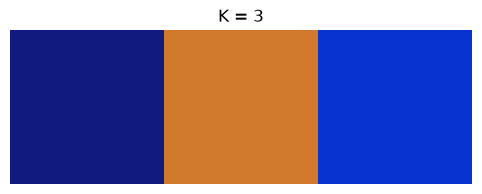

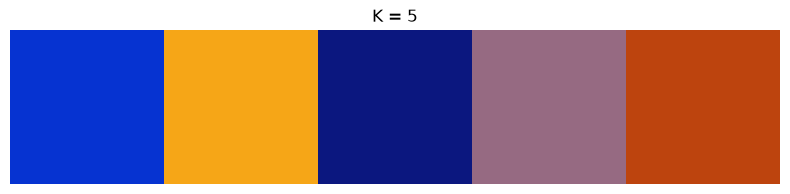

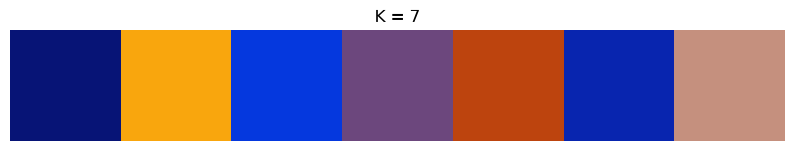

In [44]:
show_palette(palette_3, "K = 3")
show_palette(palette_5, "K = 5")
show_palette(palette_7, "K = 7")

In [45]:
lab_pixels = image_lab.reshape(-1, 3)

sample_lab_pixels = lab_pixels[sample_indices]

print(sample_lab_pixels.shape)

(50000, 3)


In [46]:
kmeans_lab_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_lab_5.fit(sample_lab_pixels)

print("LAB centroids:")
print(kmeans_lab_5.cluster_centers_)

print("\nLAB inertia:")
print(kmeans_lab_5.inertia_)

LAB centroids:
[[ 17.90641883  36.71201053 -56.44980693]
 [ 51.00914602  44.29341617  55.50723763]
 [ 31.54045988  50.10197736 -82.12794051]
 [ 77.81156718  13.73959125  73.78943589]
 [ 48.29484333  21.28997     -2.22431482]]

LAB inertia:
10440254.646602761


In [47]:
lab_centers = kmeans_lab_5.cluster_centers_

lab_centers_reshaped = lab_centers.reshape(1, -1, 3)

rgb_centers = color.lab2rgb(lab_centers_reshaped)

rgb_centers = rgb_centers.reshape(-1, 3) * 255

print(rgb_centers)

[[ 24.32258842  26.06037593 127.99255612]
 [203.40806649  84.79700479  20.87177912]
 [  9.96847637  50.00065898 207.7155642 ]
 [248.34362295 180.18557505  39.6782455 ]
 [147.7384474  101.59092167 119.02788509]]


In [48]:
labels = kmeans_lab_5.labels_

cluster_counts = np.bincount(labels)

cluster_percentages = cluster_counts / len(labels) * 100

print("Cluster counts:")
print(cluster_counts)

print("\nCluster percentages:")
print(cluster_percentages)

Cluster counts:
[16874  5439 19866  3841  3980]

Cluster percentages:
[33.748 10.878 39.732  7.682  7.96 ]


In [50]:
rgb_kmeans_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

rgb_kmeans_5.fit(sample_pixels)

rgb_cluster_counts = np.bincount(rgb_kmeans_5.labels_)

rgb_cluster_percentages = (
    rgb_cluster_counts / len(rgb_kmeans_5.labels_) * 100
)

print("RGB cluster counts:")
print(rgb_cluster_counts)

print("\nRGB cluster percentages:")
print(rgb_cluster_percentages)

RGB cluster counts:
[19156  4930 17320  4232  4362]

RGB cluster percentages:
[38.312  9.86  34.64   8.464  8.724]


In [51]:
print(rgb_kmeans_5.labels_.shape)
print(rgb_kmeans_5.labels_[:20])

(50000,)
[2 2 2 4 2 0 0 0 1 4 0 0 4 2 2 2 2 0 1 2]


In [52]:
pixel_index = 0

label = rgb_kmeans_5.labels_[pixel_index]
pixel = sample_pixels[pixel_index]
centroid = rgb_kmeans_5.cluster_centers_[label]

print("Original pixel:", pixel)
print("Cluster label:", label)
print("Representative color:", centroid)

Original pixel: [  0  21 148]
Cluster label: 2
Representative color: [ 11.40459823  23.97799087 127.429669  ]


In [53]:
pixel_index = 0

label = rgb_kmeans_5.labels_[pixel_index]
pixel = sample_pixels[pixel_index]
centroid = rgb_kmeans_5.cluster_centers_[label]

print("Original pixel:", pixel)
print("Cluster label:", label)
print("Representative color:", centroid)

Original pixel: [  0  21 148]
Cluster label: 2
Representative color: [ 11.40459823  23.97799087 127.429669  ]


In [54]:
reconstructed_pixels = rgb_kmeans_5.cluster_centers_[
    rgb_kmeans_5.labels_
]

print(reconstructed_pixels.shape)

(50000, 3)


In [55]:
all_labels = rgb_kmeans_5.predict(pixels)

print(all_labels.shape)

(9980928,)


In [57]:
reconstructed_image = rgb_kmeans_5.cluster_centers_[all_labels]

print(reconstructed_image.shape)

(9980928, 3)


In [58]:
reconstructed_image = reconstructed_image.reshape(image_array.shape)

print(reconstructed_image.shape)

(2736, 3648, 3)


In [60]:
reconstructed_display = reconstructed_image / 255.0

print(reconstructed_display.shape)

(2736, 3648, 3)


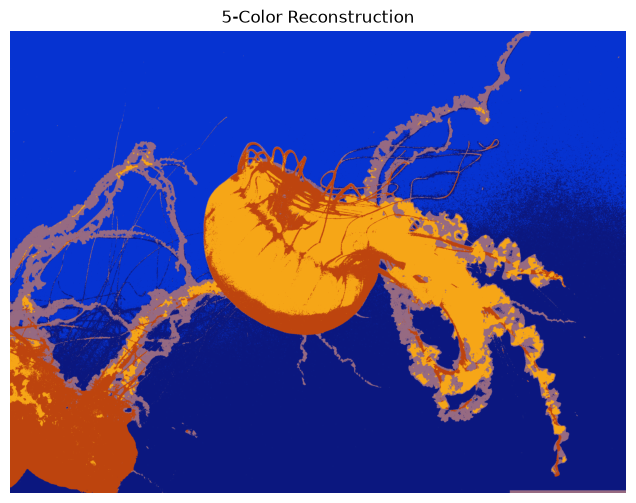

In [61]:
plt.figure(figsize=(12, 6))

plt.imshow(reconstructed_display)
plt.title("5-Color Reconstruction")
plt.axis("off")

plt.show()

In [62]:
mse = np.mean(
    (image_array.astype(float) - reconstructed_image) ** 2
)

print("Reconstruction MSE:", mse)

Reconstruction MSE: 484.1989044516475
